# 04 · Explainability with SHAP

**Goal:** understand *why* the model predicts churn, globally and for each customer.
The per-customer reason feeds the **action list** of the dashboard.

Note: the saved model was refit on all customers, so these explanations describe the model used in the dashboard.

In [8]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # lets the notebook import src/

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

sns.set_theme(style="whitegrid")
ACCENT = "#941B50"
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)

In [9]:
import joblib
import shap
from src.explain import global_importance, shap_by_original_column, top_reasons
from src.train import load_xy

bundle = joblib.load(config.MODEL_PATH)
model, threshold = bundle["model"], bundle["threshold"]
X, y = load_xy()
print("Threshold:", threshold)

Threshold: 0.25


## 1. Global drivers (mean |SHAP| per original variable)

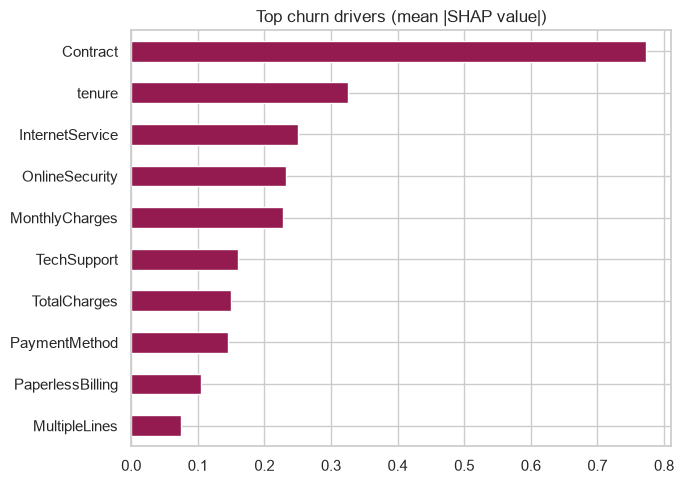

In [10]:
shap_cols = shap_by_original_column(model, X)
importance = global_importance(shap_cols, top=10)

importance.sort_values().plot.barh(color=ACCENT, figsize=(7, 5))
plt.title("Top churn drivers (mean |SHAP value|)")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "04_shap_importance.png", dpi=150); plt.show()

importance.round(3).to_csv(config.ROOT / "reports" / "shap_importance.csv")  # can be loaded into Power BI

## 2. Direction of the effects (beeswarm on the encoded features)

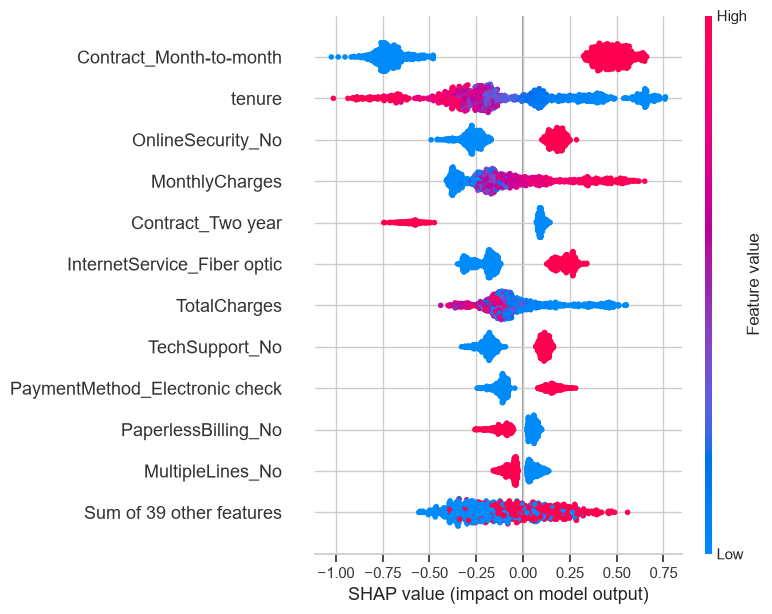

In [11]:
prep, xgb = model.named_steps["prep"], model.named_steps["model"]
sample = X.sample(1000, random_state=config.RANDOM_STATE)
X_enc = pd.DataFrame(prep.transform(sample), columns=prep.get_feature_names_out())
X_enc.columns = [c.split("__", 1)[1] for c in X_enc.columns]

explainer = shap.TreeExplainer(xgb)
values = explainer(X_enc)
shap.plots.beeswarm(values, max_display=12, show=False)
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "04_shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()

How to read it: each dot is a customer. Red = high value of the feature, blue = low value.
Dots on the right **increase** churn risk. Example: low `tenure` (blue) on the right means new customers churn more.

## 3. Main reason for each customer

In [12]:
reasons = top_reasons(shap_cols, X)
result = X[["Contract", "tenure", "MonthlyCharges"]].assign(
    ChurnProbability=model.predict_proba(X)[:, 1].round(3), TopRiskReason=reasons)
result.sort_values("ChurnProbability", ascending=False).head(10)

,Contract,tenure,MonthlyCharges,ChurnProbability,TopRiskReason
2208,Month-to-month,1,100.80,0.901,Contract: Month-to-month
6482,Month-to-month,1,101.45,0.896,Contract: Month-to-month
4800,Month-to-month,1,94.00,0.892,Contract: Month-to-month
3380,Month-to-month,1,95.10,0.891,Contract: Month-to-month
1976,Month-to-month,1,93.55,0.891,Contract: Month-to-month
4585,Month-to-month,1,85.05,0.886,Contract: Month-to-month
3209,Month-to-month,1,93.85,0.883,Contract: Month-to-month
6866,Month-to-month,1,95.45,0.883,Contract: Month-to-month
2577,Month-to-month,1,94.60,0.883,Contract: Month-to-month
6623,Month-to-month,1,76.45,0.880,Contract: Month-to-month


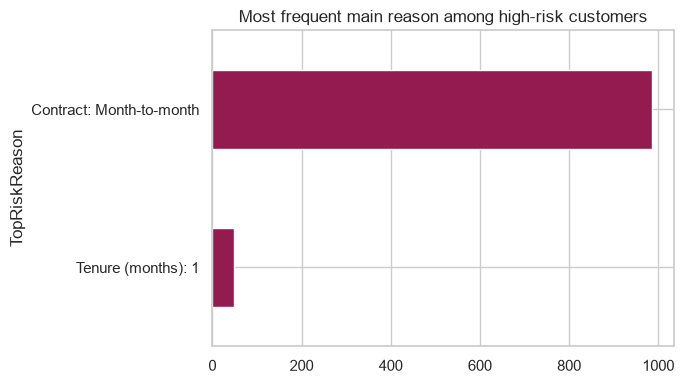

In [13]:
high_risk = result[result["ChurnProbability"] >= 0.6]
high_risk["TopRiskReason"].value_counts().head(10).sort_values().plot.barh(color=ACCENT, figsize=(7, 4))
plt.title("Most frequent main reason among high-risk customers")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "04_top_reasons.png", dpi=150); plt.show()

## 4. Explaining one customer (waterfall)

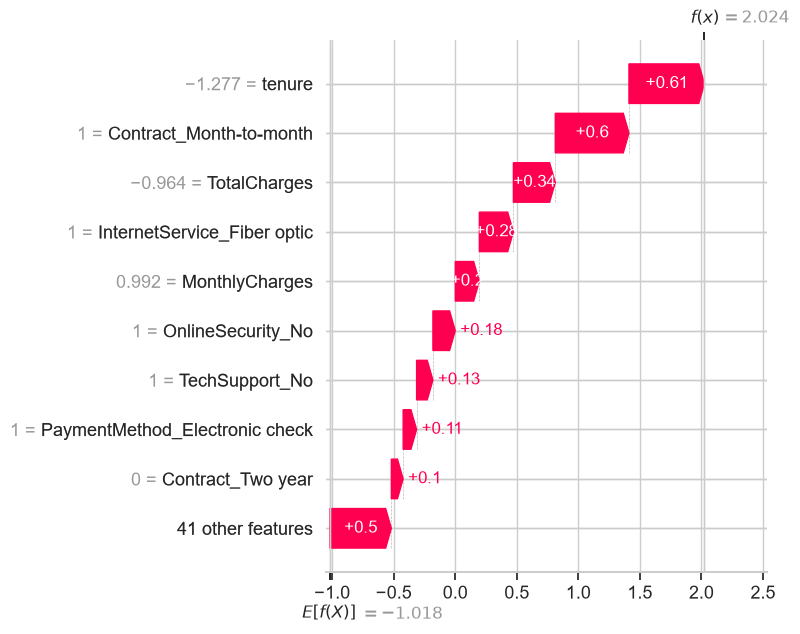

In [14]:
i = int(np.argmax(model.predict_proba(sample)[:, 1]))  # riskiest customer of the sample
shap.plots.waterfall(values[i], max_display=10, show=False)
plt.tight_layout(); plt.show()

## 5. Takeaways

**Choice of k:** k = 4 gives the best silhouette score (0.425 vs 0.419 for k = 3 and 0.386 for k = 5)
and the elbow bends around 4, so 4 segments is both statistically and business-wise a good choice.

**The 4 segments:**

| Segment | Customers | Avg tenure | Avg monthly | Services | Churn rate | Month-to-month |
|---|---|---|---|---|---|---|
| **New, high bill** | 2,410 | 15 months | $77 | 4.3 | **47%** | 86% |
| **New, low bill** | 1,509 | 10 months | $29 | 1.7 | 24% | 72% |
| **Loyal, high bill** | 2,152 | 57 months | $91 | 6.7 | 16% | 26% |
| **Loyal, low bill** | 972 | 54 months | $30 | 2.1 | **4%** | 16% |

**Key insights:**

- **"New, high bill" is the priority segment:** it has the highest churn rate (47%) and holds
  **1,162 of the 1,488 high-risk customers (78%)**. These customers pay a lot but are not yet
  committed (86% month-to-month).
  → Action: offer a discount or a free month in exchange for a one-year contract.
- **"Loyal, high bill" is the most valuable segment** ($91/month, 6.7 services) with low churn (16%).
  → Action: protect it with loyalty rewards, without costly discounts.
- **"New, low bill"** has moderate churn (24%) and few services.
  → Action: upsell protection services (OnlineSecurity, TechSupport), which reduce churn.
- **"Loyal, low bill"** is very stable (4% churn, 0 high-risk customers): no action needed.

Segmentation confirms the SHAP results (notebook 04): the risk is concentrated in **new customers
on month-to-month contracts**, especially those with high bills.
